# Assignment 1 — Image Processing Fundamentals

## Setup

In [54]:
%pip install imagecodecs

   ---------------------------------------- 0.0/19.1 MB ? eta -:--:--
   ---------------------------------------  18.9/19.1 MB 101.1 MB/s eta 0:00:01
   ---------------------------------------- 19.1/19.1 MB 78.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, util
from PIL import Image


| Import | Purpose |
|---|---|
| `Path` | Constructs paths to your files |
| `np` | Works with the numerical arrays representing images |
| `plt` | Displays images and plots |
| `io` | Reads and writes image data |
| `color` | Converts between colour representations |
| `util` | Converts image data types and intensity scales |

## A. Image types and file formats

<Peppers> | Shape (384, 512, 3)  | Type  uint8  | Minimum Value Present  0  | Maximum Value Present  255
<Cameraman> | Shape (256, 256)  | Type  uint8  | Minimum Value Present  7  | Maximum Value Present  253


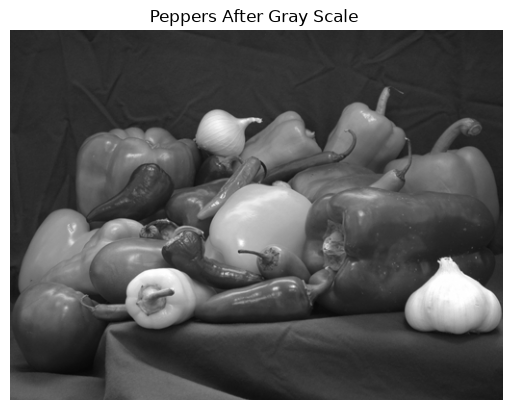

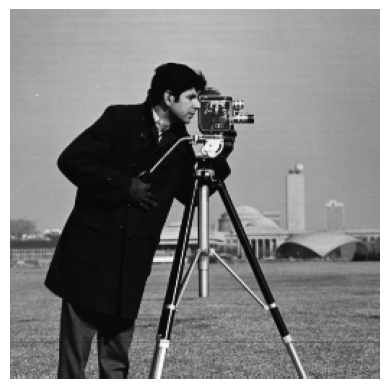

In [2]:
##################
##      A1      ##
##################

#loads images into a numpy array (via io.imread)
original_peppers = io.imread(Path("data") / "peppers.png")
original_cameraman = io.imread(Path("data") / "cameraman.tif")

#display image details
print("<Peppers> | Shape", original_peppers.shape, " | Type ", original_peppers.dtype, " | Minimum Value Present ", original_peppers.min()," | Maximum Value Present ", original_peppers.max())
print("<Cameraman> | Shape", original_cameraman.shape, " | Type ", original_cameraman.dtype, " | Minimum Value Present ", original_cameraman.min()," | Maximum Value Present ", original_cameraman.max())

#convert peppers rgb to gray at a normalized 0 - 1 scale
original_pepper_gray = color.rgb2gray(original_peppers)

#display peppers after gray transformation
plt.figure()
#ensure "imshow" doesn't apply a default color map, vmin and vmax sets display range
plt.imshow(original_pepper_gray, cmap ="gray", vmin = 0, vmax =1)
plt.title("Peppers After Gray Scale ")
plt.axis("off")
plt.show()

#display Cameraman 
plt.figure()
#ensure "imshow" doesn't apply a default color map, vmin and vmax sets display range (uint8 is 0-255)
plt.imshow(original_cameraman, cmap ="gray", vmin = 0, vmax = 255)
plt.axis("off")
plt.show()


In [3]:
##################
##      A2      ##
##################

#convert from 0-1 (floating point values, end up mixing rounding error from conversion and error from compression) to 8-bit (0-255) scale
original_pepper_gray = util.img_as_ubyte(original_pepper_gray)

#create output path if necessary via mkdir
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
#creates Pillow image from Numpy array
image_to_save = Image.fromarray(original_pepper_gray)

#lossless, tif and png, note lzw compression is lossless
image_to_save.save(output_dir / "original_pepper_gray.png")
image_to_save.save(output_dir / "original_pepper_gray.tif",compression="tiff_lzw")
#95, 75, and 50 qualities
image_to_save.save(output_dir / "original_pepper_gray_90.jpg", quality=90)
image_to_save.save(output_dir / "original_pepper_gray_75.jpg", quality=75)
image_to_save.save(output_dir / "original_pepper_gray_50.jpg", quality=50)

filenames = [
    "original_pepper_gray.png",
    "original_pepper_gray.tif",
    "original_pepper_gray_90.jpg",
    "original_pepper_gray_75.jpg",
    "original_pepper_gray_50.jpg"
]
for filename in filenames:
    saved_path = output_dir / filename
    file_size_bytes = saved_path.stat().st_size
    print(f"{filename}: {file_size_bytes} bytes")

original_pepper_gray.png: 96970 bytes
original_pepper_gray.tif: 146908 bytes
original_pepper_gray_90.jpg: 33173 bytes
original_pepper_gray_75.jpg: 18818 bytes
original_pepper_gray_50.jpg: 12422 bytes


MSE: 0.00000000
PSNR: inf dB
MSE: 0.00000000
PSNR: inf dB
MSE: 0.00003490
PSNR: 44.57 dB
MSE: 0.00007937
PSNR: 41.00 dB
MSE: 0.00013796
PSNR: 38.60 dB


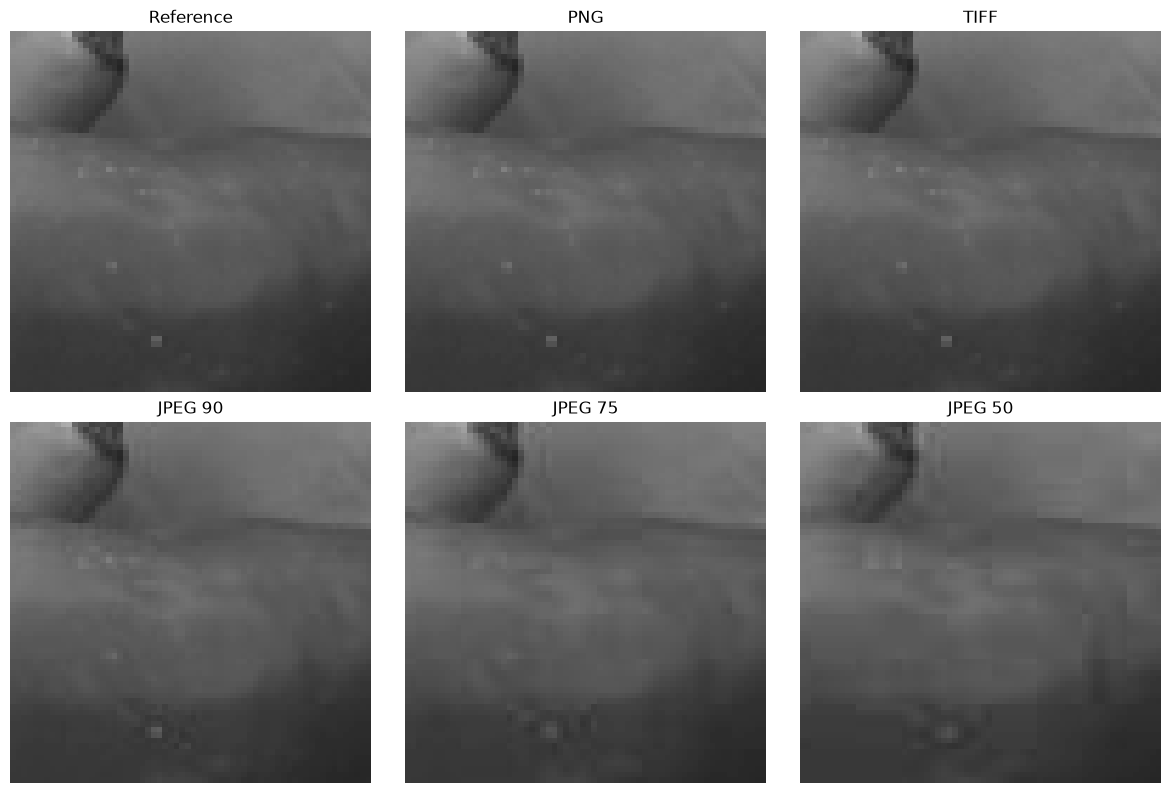

In [ ]:
##################
##      A3     ##
##################
outputs_path = "outputs"
gray_peppers_png = io.imread(Path(outputs_path) / "original_pepper_gray.png")
gray_peppers_tif = io.imread(Path(outputs_path) / "original_pepper_gray.tif")
gray_peppers_jpg_90 = io.imread(Path(outputs_path) / "original_pepper_gray_90.jpg")
gray_peppers_jpg_75 = io.imread(Path(outputs_path) / "original_pepper_gray_75.jpg")
gray_peppers_jpg_50 = io.imread(Path(outputs_path) / "original_pepper_gray_50.jpg")

peppers_file_types = [
    gray_peppers_png,
    gray_peppers_tif,
    gray_peppers_jpg_90,
    gray_peppers_jpg_75,
    gray_peppers_jpg_50
]

### MSE & PSNR between original_pepper_gray and [array]
for filetype in peppers_file_types:
    #convert to float on 0-1 scale for all images
    reference = util.img_as_float(original_pepper_gray)
    reloaded = util.img_as_float(filetype)

    #MSE calculation
    mse = np.mean((reference - reloaded)**2)
    print(f"MSE: {mse:.8f}")

    # Peak signal-to-noise ratio; maximum intensity is 1 on this scale
    if mse == 0:
        psnr = np.inf
    else:
        psnr = 10 * np.log10(1.0 ** 2 / mse)
    print(f"PSNR: {psnr:.2f} dB")

### Cropping (Selecting a smaller rectangle from an array)

#USED TO FIND A SUITABLE LOCATION OF COMPRESSION ARTIFACTS
#plt.figure(figsize=(10, 8))
#plt.imshow(gray_peppers_png, cmap="gray", vmin=0, vmax=255)
#plt.title("Choose a crop: x = column, y = row")
#plt.show()

#plt.figure(figsize=(10, 8))
#plt.imshow(gray_peppers_jpg_50, cmap="gray", vmin=0, vmax=255)
#plt.title("Choose a crop: x = column, y = row")
#plt.show()

r0 = 150   # Starting row: y coordinate
c0 = 390   # Starting column: x coordinate
crop_size = 64

images = [
    ("Reference", original_pepper_gray),
    ("PNG", gray_peppers_png),
    ("TIFF", gray_peppers_tif),
    ("JPEG 90", gray_peppers_jpg_90),
    ("JPEG 75", gray_peppers_jpg_75),
    ("JPEG 50", gray_peppers_jpg_50),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (label, image) in zip(axes.flat, images):
    image_float = util.img_as_float(image)

    crop = image_float[r0:r0 + crop_size, c0:c0 + crop_size]

    ax.imshow( crop, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


* MSE - Compares the error/difference between the pixels at the same location. LOW = less difference, HIGH(like 1) = more difference
* PSNR - Gives the noise gained through the saving and reconstructing of the image. LOW = more reconstruction error, HIGH(inf) = less reconstruction error

Global threshold: 0.49356617647058826
Global: foreground = 22344, background = 51456, total = 73800
Global inverted: foreground = 51456, background = 22344, total = 73800
Adaptive: foreground = 27897, background = 45903, total = 73800
Adaptive inverted: foreground = 45903, background = 27897, total = 73800


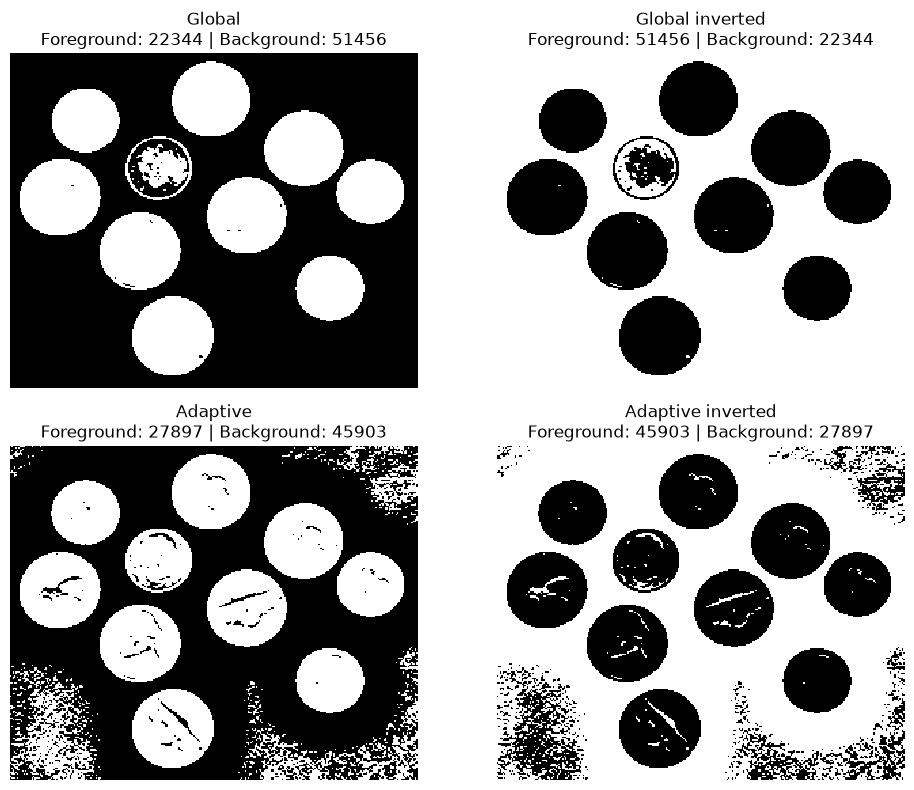

In [ ]:
##################
##      A4      ##
##################
from skimage import filters

coins = io.imread(Path("data") / "coins.png")
coins_float = util.img_as_float(coins)

# Global
global_threshold = filters.threshold_otsu(coins_float)
print("Global threshold:", global_threshold)
global_mask = coins_float > global_threshold
#   Inversion
global_inverted = ~global_mask

# Adaptive
#the higher the block size the more it is averaging over, it becomes easier to see the individual coins but the faces become obscurred
local_thresholds = filters.threshold_local(coins_float, block_size=83)
adaptive_mask = coins_float > local_thresholds
#   Inversion
adaptive_inverted = ~adaptive_mask

# Pair each display label with its Boolean mask
results = [
    ("Global", global_mask),
    ("Global inverted", global_inverted),
    ("Adaptive", adaptive_mask),
    ("Adaptive inverted", adaptive_inverted)
]

# Create four plotting panels
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Visit each panel and its corresponding mask
for ax, (label, mask) in zip(axes.flat, results):

    # True pixels are foreground; False pixels are background
    foreground = np.count_nonzero(mask)
    background = mask.size - foreground

    print(
        f"{label}: foreground = {foreground}, "
        f"background = {background}, total = {mask.size}"
    )

    # Display False as black and True as white
    ax.imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        f"{label}\n"
        f"Foreground: {foreground} | Background: {background}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## B. Intensity transforms and geometry

## C. Spatial filtering

## D. Frequency-domain filtering

## E. Edge detection and robotics mini task

## F. Reflection